# [EDA] 지역·인구 프로파일링 — 2026-09-20

**작성자** — 김태은 (`taeeunni`)

**핵심 질문** — 강남구와 춘천시는 어떻게 다른가. 타겟 지역 결정의 근거를 만든다.

**설계상 제약** — SK는 행정동 47개까지 내려가지만 신한카드는 시군구 2개뿐이다.
두 데이터를 동 단위에서 결합하면 n=2가 되어 통계가 성립하지 않는다.
따라서 공간축(SK, 동 47개)과 집단축(카드, 지역×성×연령 36집단)을 **분리**해 프로파일링한다.

In [1]:
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import loaders, paths, regions
from src.features import card_cohort, isolation, sk_dong
from src.visualization.style import PALETTE, SGG_COLORS, setup_style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

FONT = setup_style()
print(f"한글 폰트: {FONT}")
print(f"pandas {pd.__version__} / numpy {np.__version__}")

한글 폰트: Malgun Gothic
pandas 3.0.6 / numpy 2.5.2


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
panel = sk_dong.build_space_panel()
panel["지역"] = panel.dong_cd.str[:5].map(regions.SGG_NAMES)
panel["age_sum"] = panel[sk_dong.AGE_COLS].sum(axis=1)
card = card_cohort.prepare_card(2)
cohort = card_cohort.cohort_panel(card)
print(f"공간축 패널: {len(panel)}행 (동 {panel.dong_cd.nunique()} x 월 {panel.STD_YM.nunique()})")
print(f"집단축 패널: {len(cohort)}행")
print(panel.groupby("지역").dong_cd.nunique().to_string())

공간축 패널: 282행 (동 47 x 월 6)
집단축 패널: 216행
지역
강원 춘천시    25
서울 강남구    22


## 1. 강남 vs 춘천 대조

In [3]:
AGE_LABELS = ["10대", "20대", "30대", "40대", "50대", "60대+"]
by_sgg_age = panel.groupby("지역", observed=True)[sk_dong.AGE_COLS].sum()
share = by_sgg_age.div(by_sgg_age.sum(axis=1), axis=0) * 100

tbl = pd.DataFrame({
    "남성%": [share.loc[z, f"MAN_FLOW_POP_CNT_{g}"]
              for z in share.index for g in ("10G", "20G", "30G", "40G", "50G", "60GU")],
}, index=pd.MultiIndex.from_product([share.index, AGE_LABELS], names=["지역", "연령"]))
tbl["여성%"] = [share.loc[z, f"WMAN_FLOW_POP_CNT_{g}"]
                for z in share.index for g in ("10G", "20G", "30G", "40G", "50G", "60GU")]
tbl["합계%"] = tbl["남성%"] + tbl["여성%"]
print("지역별 성·연령 구성비 (유동인구 기준)")
print(tbl.round(2).to_string())

지역별 성·연령 구성비 (유동인구 기준)
               남성%    여성%    합계%
지역     연령                       
강원 춘천시 10대   7.420  6.910 14.330
       20대   7.340  6.760 14.090
       30대   6.380  6.090 12.460
       40대   8.560  8.280 16.840
       50대   9.200  8.420 17.620
       60대+ 11.960 12.690 24.660
서울 강남구 10대   4.400  4.550  8.950
       20대   6.600  8.800 15.400
       30대   9.770  9.510 19.280
       40대  10.960  9.480 20.440
       50대   9.730  7.340 17.070
       60대+  9.820  9.050 18.860


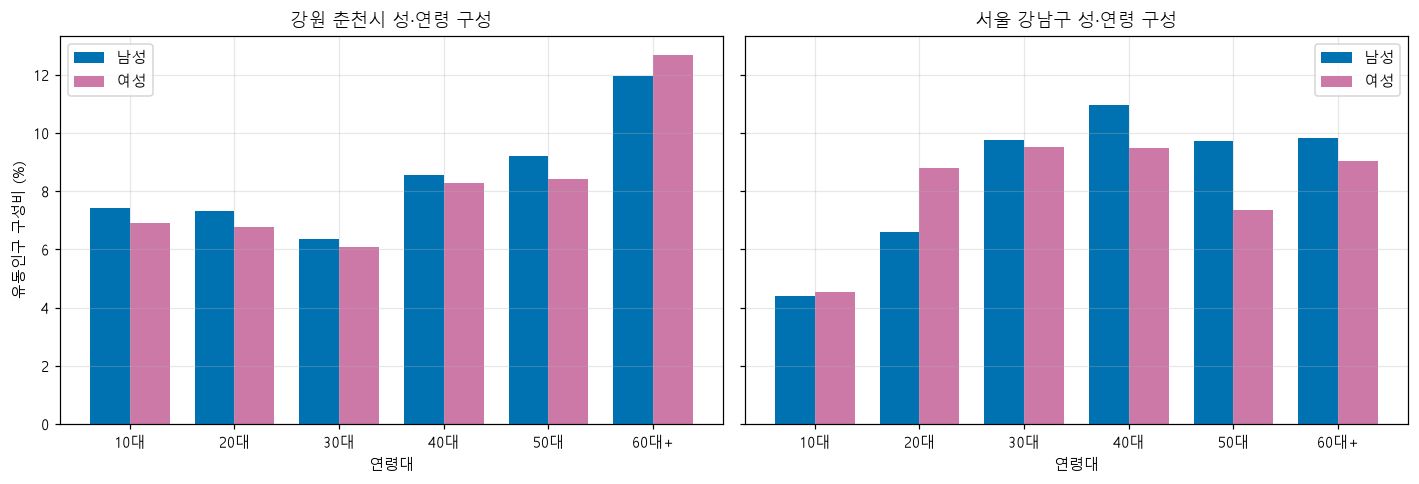

60대 이상 비중 — 강남 18.86% / 춘천 24.66%
춘천이 강남보다 5.79%p 높다


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
x = np.arange(len(AGE_LABELS))
w = 0.38
for ax, z in zip(axes, share.index):
    m = [share.loc[z, f"MAN_FLOW_POP_CNT_{g}"] for g in ("10G", "20G", "30G", "40G", "50G", "60GU")]
    f = [share.loc[z, f"WMAN_FLOW_POP_CNT_{g}"] for g in ("10G", "20G", "30G", "40G", "50G", "60GU")]
    ax.bar(x - w / 2, m, w, label="남성", color=PALETTE[0])
    ax.bar(x + w / 2, f, w, label="여성", color=PALETTE[3])
    ax.set_title(f"{z} 성·연령 구성")
    ax.set_xticks(x)
    ax.set_xticklabels(AGE_LABELS)
    ax.set_xlabel("연령대")
    ax.legend()
axes[0].set_ylabel("유동인구 구성비 (%)")
plt.tight_layout()
plt.show()

senior = tbl.xs("60대+", level="연령")["합계%"]
print(f"60대 이상 비중 — 강남 {senior['서울 강남구']:.2f}% / 춘천 {senior['강원 춘천시']:.2f}%")
print(f"춘천이 강남보다 {senior['강원 춘천시'] - senior['서울 강남구']:.2f}%p 높다")

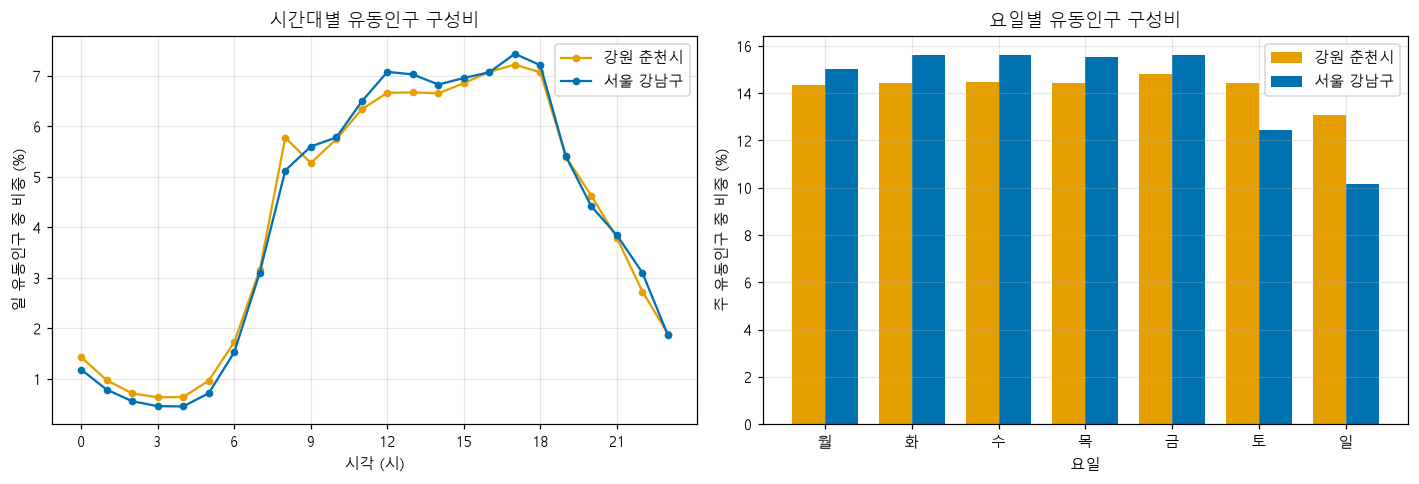

시간대 구성비
        TMST_00  TMST_01  TMST_02  TMST_03  TMST_04  TMST_05  TMST_06  TMST_07  TMST_08  TMST_09  TMST_10  TMST_11  TMST_12  TMST_13  TMST_14  TMST_15  TMST_16  TMST_17  TMST_18  TMST_19  TMST_20  TMST_21  TMST_22  TMST_23
지역                                                                                                                                                                                                                            
강원 춘천시    1.430    0.970    0.710    0.630    0.640    0.960    1.730    3.160    5.780    5.270    5.740    6.340    6.660    6.670    6.650    6.850    7.080    7.220    7.070    5.400    4.620    3.790    2.730    1.900
서울 강남구    1.180    0.790    0.560    0.460    0.450    0.720    1.530    3.100    5.120    5.600    5.780    6.490    7.080    7.030    6.830    6.960    7.070    7.440    7.210    5.400    4.410    3.840    3.100    1.860

요일 구성비
        FLOW_POP_CNT_MON  FLOW_POP_CNT_TUS  FLOW_POP_CNT_WED  FLOW_POP_CNT_THU  FLOW_POP_CNT

In [5]:
by_sgg_time = panel.groupby("지역", observed=True)[sk_dong.TIME_COLS].sum()
tshare = by_sgg_time.div(by_sgg_time.sum(axis=1), axis=0) * 100
by_sgg_wkdy = panel.groupby("지역", observed=True)[sk_dong.WKDY_COLS].sum()
wshare = by_sgg_wkdy.div(by_sgg_wkdy.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for z in tshare.index:
    ax.plot(range(24), tshare.loc[z], marker="o", ms=4, label=z, color=SGG_COLORS[z])
ax.set_title("시간대별 유동인구 구성비")
ax.set_xlabel("시각 (시)")
ax.set_ylabel("일 유동인구 중 비중 (%)")
ax.set_xticks(range(0, 24, 3))
ax.legend()

ax = axes[1]
DAYS = ["월", "화", "수", "목", "금", "토", "일"]
x = np.arange(7)
for i, z in enumerate(wshare.index):
    ax.bar(x + (i - 0.5) * 0.38, wshare.loc[z], 0.38, label=z, color=SGG_COLORS[z])
ax.set_title("요일별 유동인구 구성비")
ax.set_xlabel("요일")
ax.set_ylabel("주 유동인구 중 비중 (%)")
ax.set_xticks(x)
ax.set_xticklabels(DAYS)
ax.legend()
plt.tight_layout()
plt.show()

print("시간대 구성비")
print(tshare.round(2).to_string())
print()
print("요일 구성비")
print(wshare.round(2).to_string())

## 2. 고령층 비중

60대 이상 유동 비중이 높은 동을 찾는다. 고립 위험군 탐색의 1차 후보다.

In [6]:
ind = isolation.space_indicators(panel)
ind["지역"] = ind.dong_cd.str[:5].map(regions.SGG_NAMES)
ind = ind.sort_values("senior_share", ascending=False)

print("60대 이상 유동 비중 상위 15개 행정동")
print(ind.head(15)[["dong_cd", "지역", "senior_share", "total"]].assign(
    senior_share_pct=lambda d: (d.senior_share * 100).round(2)).drop(
    columns="senior_share").round({"total": 0}).to_string(index=False))
print()
print("지역별 senior_share 요약")
print((ind.groupby("지역").senior_share.describe(percentiles=[0.5]) * 100).round(2).to_string())

60대 이상 유동 비중 상위 15개 행정동
 dong_cd     지역       total  senior_share_pct
32010390 강원 춘천시   4,597.000            49.520
32010380 강원 춘천시  11,207.000            41.340
32010110 강원 춘천시  37,115.000            37.740
32010370 강원 춘천시  25,418.000            36.860
32010330 강원 춘천시  26,660.000            30.490
32010350 강원 춘천시  14,763.000            29.710
11230750 서울 강남구 243,772.000            29.350
32010360 강원 춘천시  38,458.000            29.270
11230730 서울 강남구  98,771.000            28.860
32010320 강원 춘천시  30,465.000            28.300
11230720 서울 강남구 195,811.000            27.450
32010630 강원 춘천시  26,403.000            27.280
11230740 서울 강남구 130,374.000            26.770
32010540 강원 춘천시  53,363.000            26.770
32010710 강원 춘천시 128,594.000            26.280

지역별 senior_share 요약
           count   mean   std    min    50%    max
지역                                                
강원 춘천시 2,500.000 27.740 6.890 20.390 25.330 49.520
서울 강남구 2,200.000 21.250 4.910 14.210 20.180 29.350


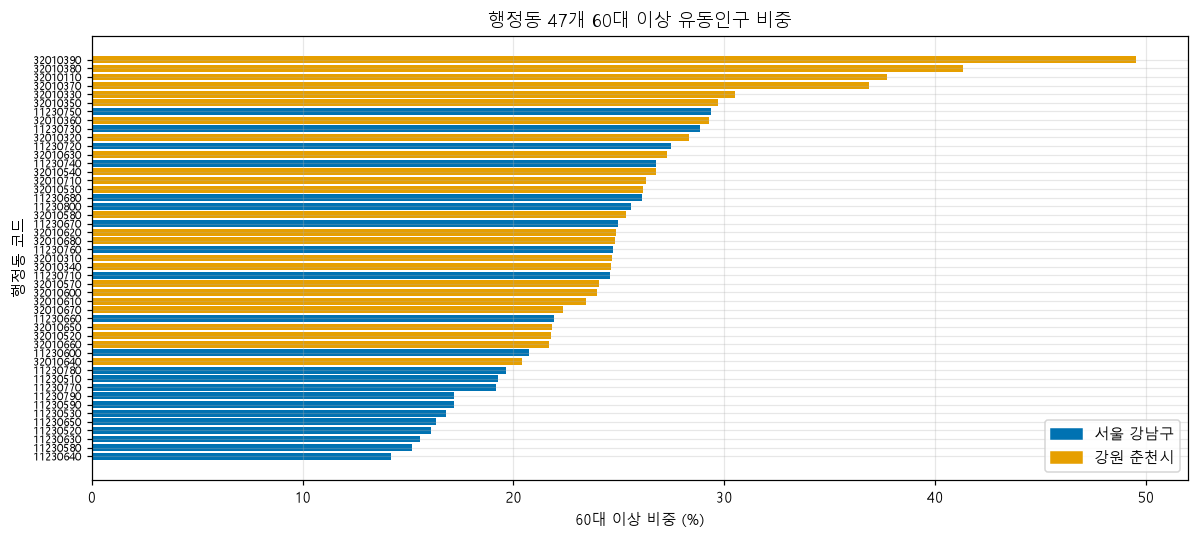

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
dd = ind.sort_values("senior_share")
colors = [SGG_COLORS[z] for z in dd.지역]
ax.barh(range(len(dd)), dd.senior_share * 100, color=colors)
ax.set_yticks(range(len(dd)))
ax.set_yticklabels(dd.dong_cd, fontsize=7)
ax.set_title("행정동 47개 60대 이상 유동인구 비중")
ax.set_xlabel("60대 이상 비중 (%)")
ax.set_ylabel("행정동 코드")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SGG_COLORS.values()]
ax.legend(handles, list(SGG_COLORS), loc="lower right")
plt.tight_layout()
plt.show()

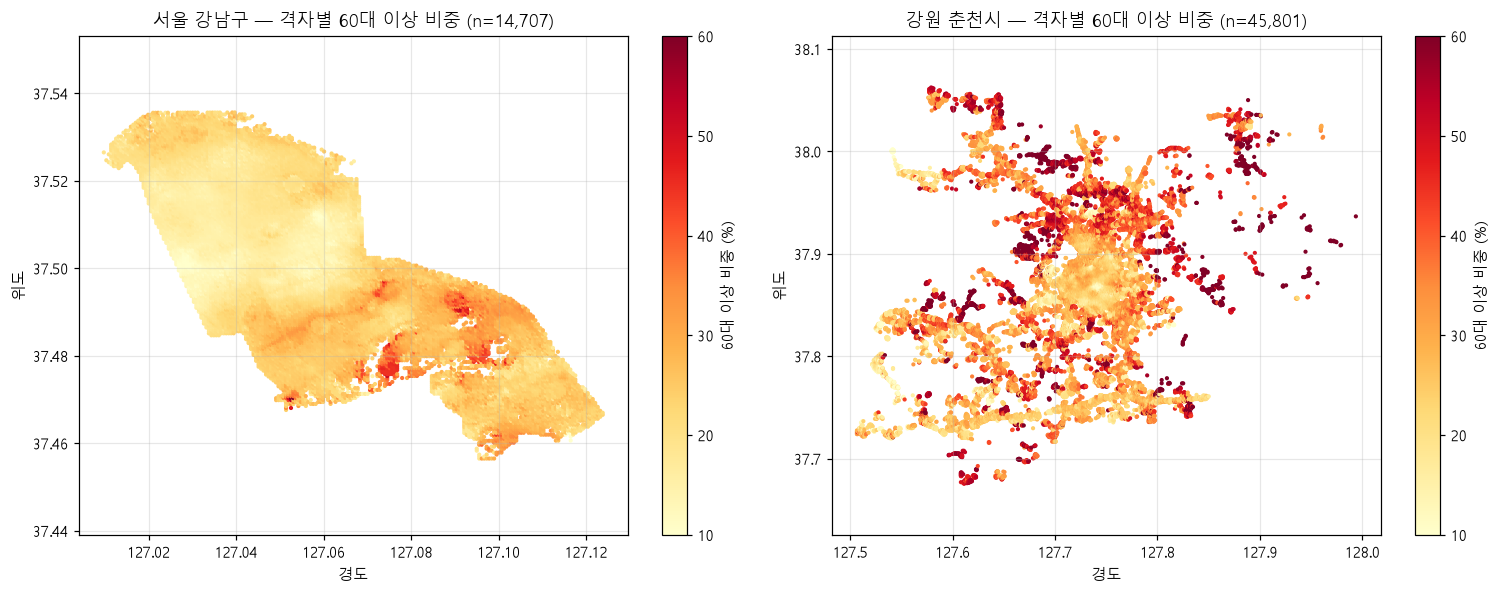

유동인구 1명 초과 격자만 표시했다 (노이즈 제거)


In [8]:
# 격자 좌표 위에 고령 비중을 그린다
g = regions.add_wgs84(regions.filter_target_sgg(
    regions.add_region_codes(loaders.load_sk("age", "202507"))))
g["tot"] = g[sk_dong.AGE_COLS].sum(axis=1)
g["senior"] = g[sk_dong.SENIOR_COLS].sum(axis=1)
g = g[g.tot > 1]  # 노이즈 격자 제외
g["senior_share"] = g.senior / g.tot

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (cd, nm) in zip(axes, regions.SGG_NAMES.items()):
    sub = g[g.sgg_cd == cd]
    sc = ax.scatter(sub.lon, sub.lat, c=sub.senior_share * 100, s=3,
                    cmap="YlOrRd", vmin=10, vmax=60)
    ax.set_title(f"{nm} — 격자별 60대 이상 비중 (n={len(sub):,})")
    ax.set_xlabel("경도")
    ax.set_ylabel("위도")
    ax.set_aspect("equal", adjustable="datalim")
    plt.colorbar(sc, ax=ax, label="60대 이상 비중 (%)")
plt.tight_layout()
plt.show()
print("유동인구 1명 초과 격자만 표시했다 (노이즈 제거)")

## 3. 시간대 패턴 군집

동 47개를 24시간 프로파일로 정규화한 뒤 군집화한다.
주간 활동형 / 야간형 / 저활동 정체형을 구분하는 것이 목적이다.

In [9]:
prof = panel.groupby("dong_cd", observed=True)[sk_dong.TIME_COLS].sum()
prof_share = prof.div(prof.sum(axis=1), axis=0)  # 동별 24시간 구성비
X = StandardScaler().fit_transform(prof_share.values)

scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)
    scores[k] = silhouette_score(X, km.labels_)
print("군집 수별 실루엣 계수")
for k, s in scores.items():
    print(f"  k={k}: {s:.4f}")
best_k = max(scores, key=scores.get)
print(f"\n선택된 k = {best_k} (실루엣 최대)")

군집 수별 실루엣 계수
  k=2: 0.4230
  k=3: 0.3189
  k=4: 0.3054
  k=5: 0.3127
  k=6: 0.2797

선택된 k = 2 (실루엣 최대)


군집별 동 수
지역       강원 춘천시  서울 강남구
cluster                
0            17      20
1             8       2



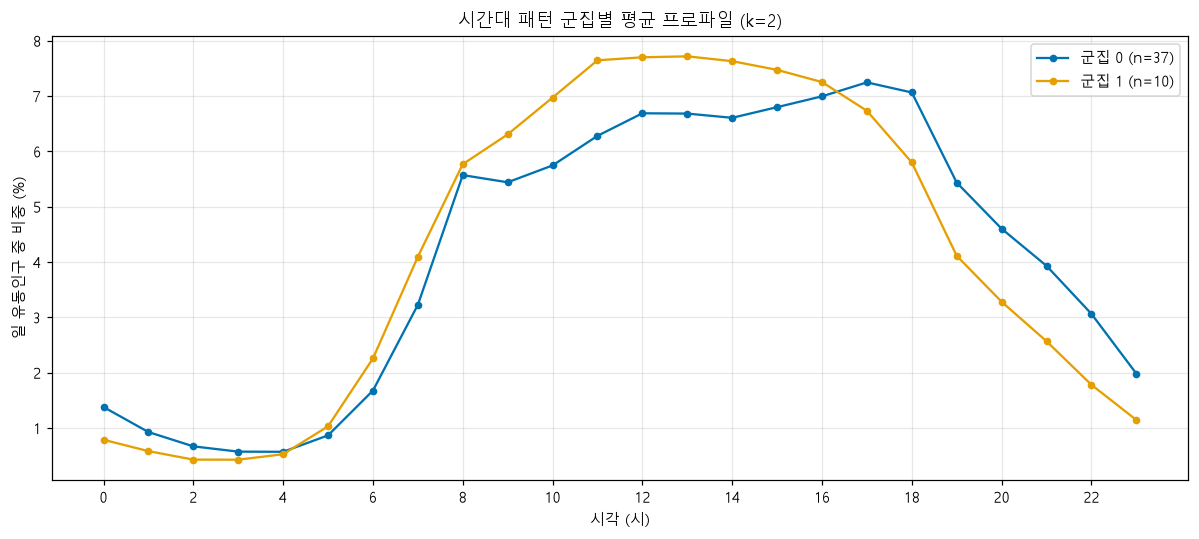

In [10]:
km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(X)
prof_share = prof_share.assign(cluster=km.labels_)
prof_share["지역"] = prof_share.index.str[:5].map(regions.SGG_NAMES)

print("군집별 동 수")
print(pd.crosstab(prof_share.cluster, prof_share.지역).to_string())
print()
cl_mean = prof_share.groupby("cluster")[sk_dong.TIME_COLS].mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
for c in sorted(prof_share.cluster.unique()):
    n = int((prof_share.cluster == c).sum())
    ax.plot(range(24), cl_mean.loc[c], marker="o", ms=4,
            label=f"군집 {c} (n={n})", color=PALETTE[c])
ax.set_title(f"시간대 패턴 군집별 평균 프로파일 (k={best_k})")
ax.set_xlabel("시각 (시)")
ax.set_ylabel("일 유동인구 중 비중 (%)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 이 군집이 실재하는 구조인가

실루엣 0.42는 절대 기준으로 '중간'이다. 네 가지로 검정한다.

In [11]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

region = np.array([regions.SGG_NAMES[d[:5]] for d in prof.index])

# A. 순열 귀무분포 — 구조가 없어도 이만한 실루엣이 나오는가
rng = np.random.default_rng(SEED)
null = []
for _ in range(300):
    Xp = np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])
    lab = KMeans(n_clusters=2, random_state=0, n_init=3).fit_predict(Xp)
    null.append(silhouette_score(Xp, lab))
null = np.array(null)
print("[A] 순열 귀무분포 (컬럼별 셔플 300회)")
print(f"    관측 실루엣 {scores[2]:.4f}")
print(f"    귀무 평균 {null.mean():.4f} / 95분위 {np.quantile(null, 0.95):.4f}")
print(f"    p값 = {(null >= scores[2]).mean():.4f}")
print("    -> 구조 없음으로는 설명되지 않는다")

[A] 순열 귀무분포 (컬럼별 셔플 300회)
    관측 실루엣 0.4230
    귀무 평균 0.0553 / 95분위 0.0715
    p값 = 0.0000
    -> 구조 없음으로는 설명되지 않는다


In [12]:
# B. 부트스트랩 안정성
base = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit_predict(X)
aris = []
for b in range(300):
    idx = np.unique(rng.choice(len(X), size=len(X), replace=True))
    lab_b = KMeans(n_clusters=2, random_state=b, n_init=5).fit_predict(X[idx])
    aris.append(adjusted_rand_score(base[idx], lab_b))
aris = np.array(aris)
print("[B] 부트스트랩 300회 (ARI 1.0=완전 재현)")
print(f"    평균 {aris.mean():.4f} / 중앙값 {np.median(aris):.4f} / 5분위 {np.quantile(aris, 0.05):.4f}")
print(f"    ARI>=0.75 비율 {(aris >= 0.75).mean() * 100:.1f}%")
print("    -> 통상 0.75 이상이면 안정적 군집으로 본다")

[B] 부트스트랩 300회 (ARI 1.0=완전 재현)
    평균 0.8808 / 중앙값 1.0000 / 5분위 0.5570
    ARI>=0.75 비율 84.3%
    -> 통상 0.75 이상이면 안정적 군집으로 본다


In [13]:
# C. 알고리즘 교차
algos = {
    "KMeans": base,
    "Ward": AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X),
    "Average": AgglomerativeClustering(n_clusters=2, linkage="average").fit_predict(X),
    "GMM": GaussianMixture(n_components=2, random_state=SEED, n_init=10).fit_predict(X),
}
mat = pd.DataFrame(
    [[round(adjusted_rand_score(a, b), 3) for b in algos.values()] for a in algos.values()],
    index=list(algos), columns=list(algos))
print("[C] 알고리즘 간 ARI")
print(mat.to_string())
print()
for nm, lab in algos.items():
    print(f"    {nm:8s} 군집 크기 {np.bincount(lab).tolist()}  실루엣 {silhouette_score(X, lab):.4f}")

[C] 알고리즘 간 ARI
         KMeans  Ward  Average   GMM
KMeans    1.000 0.904    0.904 1.000
Ward      0.904 1.000    1.000 0.904
Average   0.904 1.000    1.000 0.904
GMM       1.000 0.904    0.904 1.000

    KMeans   군집 크기 [37, 10]  실루엣 0.4230
    Ward     군집 크기 [38, 9]  실루엣 0.4254
    Average  군집 크기 [38, 9]  실루엣 0.4254
    GMM      군집 크기 [37, 10]  실루엣 0.4230


In [14]:
# D. 군집이 그냥 지역 구분인가
ct = pd.crosstab(pd.Series(base, name="군집"), pd.Series(region, name="지역"))
obs = ct.to_numpy().astype(float)
exp = np.outer(obs.sum(1), obs.sum(0)) / obs.sum()
chi2 = ((obs - exp) ** 2 / exp).sum()
cv = np.sqrt(chi2 / obs.sum())

print("[D] 군집 x 지역 교차표")
print(ct.to_string())
print()
for nm, lab in algos.items():
    print(f"    ARI(군집, 지역) {nm:8s} = {adjusted_rand_score(region, lab):.4f}")
print()
print(f"    Cramer's V = {cv:.4f}, chi2 = {chi2:.4f}")
rng2 = np.random.default_rng(0)
nullv = []
for _ in range(5000):
    o = pd.crosstab(pd.Series(base), pd.Series(rng2.permutation(region))).to_numpy().astype(float)
    if o.shape != (2, 2):
        continue
    e = np.outer(o.sum(1), o.sum(0)) / o.sum()
    nullv.append(np.sqrt(((o - e) ** 2 / e).sum() / o.sum()))
print(f"    지역 라벨 순열 5,000회 -> p = {(np.array(nullv) >= cv).mean():.4f}")
print()
print("    -> ARI가 0에 가까우면 군집은 지역 구분이 '아니다'")

[D] 군집 x 지역 교차표
지역  강원 춘천시  서울 강남구
군집                
0       17      20
1        8       2

    ARI(군집, 지역) KMeans   = 0.0212


    ARI(군집, 지역) Ward     = 0.0404
    ARI(군집, 지역) Average  = 0.0404
    ARI(군집, 지역) GMM      = 0.0212

    Cramer's V = 0.2793, chi2 = 3.6667


    지역 라벨 순열 5,000회 -> p = 0.0774

    -> ARI가 0에 가까우면 군집은 지역 구분이 '아니다'


In [15]:
# E. 개별 동의 군집 소속 안정성 (부트스트랩 동시출현률)
n = len(X)
co, cnt = np.zeros((n, n)), np.zeros((n, n))
for b in range(300):
    idx = np.unique(rng.choice(n, size=n, replace=True))
    lab = KMeans(n_clusters=2, random_state=b, n_init=5).fit_predict(X[idx])
    for ci in np.unique(lab):
        mem = idx[lab == ci]
        co[np.ix_(mem, mem)] += 1
    cnt[np.ix_(idx, idx)] += 1
np.fill_diagonal(co, 0)
np.fill_diagonal(cnt, 0)
stab = np.divide(co, cnt, out=np.zeros_like(co), where=cnt > 0)

minor = np.bincount(base).argmin()
mi, ma = np.where(base == minor)[0], np.where(base != minor)[0]
rows = [{"dong_cd": prof.index[i], "지역": region[i],
         "소수군집_내부": round(float(np.mean(stab[i, [j for j in mi if j != i]])), 4),
         "다수군집과": round(float(np.mean(stab[i, ma])), 4)} for i in mi]
print("[E] 소수 군집 구성원의 소속 안정성")
print(pd.DataFrame(rows).sort_values("소수군집_내부", ascending=False).to_string(index=False))
print()
print(f"    군집 간 평균 동시출현률: {np.mean([stab[i, j] for i in mi for j in ma]):.4f}")

[E] 소수 군집 구성원의 소속 안정성
 dong_cd     지역  소수군집_내부  다수군집과
32010360 강원 춘천시    0.979  0.025
32010370 강원 춘천시    0.979  0.023
32010110 강원 춘천시    0.972  0.025
32010330 강원 춘천시    0.970  0.028
32010390 강원 춘천시    0.967  0.018
32010350 강원 춘천시    0.966  0.014
32010320 강원 춘천시    0.965  0.020
32010380 강원 춘천시    0.965  0.025
11230720 서울 강남구    0.907  0.104
11230580 서울 강남구    0.784  0.248

    군집 간 평균 동시출현률: 0.0530


In [16]:
# 군집 해석 — 야간 비중과 피크 집중도로 이름을 붙인다
summ = prof_share.groupby("cluster").apply(
    lambda d: pd.Series({
        "동수": len(d),
        "야간비중%": d[sk_dong.NIGHT_COLS].sum(axis=1).mean() * 100,
        "주간피크시각": int(np.argmax(d[sk_dong.TIME_COLS].mean().values)),
        "피크비중%": d[sk_dong.TIME_COLS].max(axis=1).mean() * 100,
    }), include_groups=False)
summ = summ.join(
    ind.set_index("dong_cd").reindex(prof_share.index).groupby(prof_share.cluster).agg(
        평균총유동=("total", "mean"), 평균고령비중=("senior_share", "mean"))
)
summ["평균고령비중"] = (summ["평균고령비중"] * 100).round(2)
print("군집 특성 요약")
print(summ.round(2).to_string())
print()
for c in sorted(prof_share.cluster.unique()):
    dongs = prof_share[prof_share.cluster == c]
    print(f"군집 {c}: {list(dongs.index[:12])}{' ...' if len(dongs) > 12 else ''}")

군집 특성 요약
            동수  야간비중%  주간피크시각  피크비중%       평균총유동  평균고령비중
cluster                                                 
0       37.000 10.020  17.000  7.340 222,965.110  22.570
1       10.000  6.700  13.000  7.920  97,959.510  32.580

군집 0: ['11230510', '11230520', '11230530', '11230590', '11230600', '11230630', '11230640', '11230650', '11230660', '11230670', '11230680', '11230710'] ...
군집 1: ['11230580', '11230720', '32010110', '32010320', '32010330', '32010350', '32010360', '32010370', '32010380', '32010390']


## 4. 카드 집단 프로파일

카드는 시군구 2개뿐이므로 지역 × 성 × 연령의 36개 집단으로 프로파일링한다.

In [17]:
cind = isolation.cohort_indicators(cohort)
cind["집단"] = cind.MCT_SGG_CD + " " + cind.SEX_CCD + " " + cind.age_band.astype(str) + "대"
print(f"집단 수: {len(cind)}")
print()
print("사회적 업종 소비 비중 (미분류·비소비 제외 금액 기준, %)")
piv = cind.pivot_table(index=["MCT_SGG_CD", "SEX_CCD"], columns="age_band",
                       values="social_share") * 100
print(piv.round(2).to_string())

집단 수: 36

사회적 업종 소비 비중 (미분류·비소비 제외 금액 기준, %)
age_band               10     20     30     40     50     60     70     80     90
MCT_SGG_CD SEX_CCD                                                               
강원 춘천시     남성      43.310 39.520 30.070 25.250 24.940 22.080 18.050 17.990 19.660
           여성      42.090 37.990 26.160 23.080 22.540 18.500 16.530 17.450 20.340
서울 강남구     남성      28.660 21.830 16.280 11.050 12.190 12.310 13.030 15.370 15.400
           여성      28.730 21.350 15.510  9.960 10.620 10.480 12.660 15.420 15.710


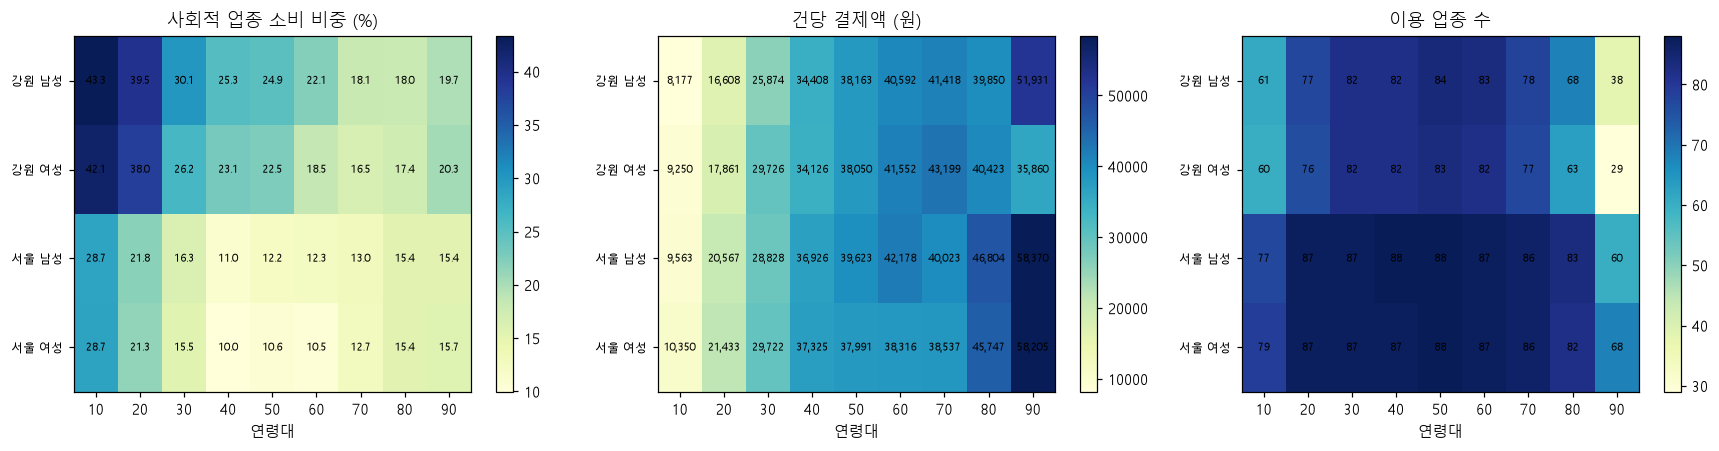

In [18]:
metrics = [("social_share", "사회적 업종 소비 비중 (%)", 100),
           ("amount_per_use", "건당 결제액 (원)", 1),
           ("ry_diversity", "이용 업종 수", 1)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, title, scale) in zip(axes, metrics):
    p = cind.pivot_table(index=["MCT_SGG_CD", "SEX_CCD"], columns="age_band",
                         values=col) * scale
    im = ax.imshow(p.values, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(p.columns)))
    ax.set_xticklabels([f"{c}" for c in p.columns])
    ax.set_yticks(range(len(p.index)))
    ax.set_yticklabels([f"{a[:2]} {b}" for a, b in p.index], fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("연령대")
    ax.grid(False)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            ax.text(j, i, f"{v:,.0f}" if scale == 1 else f"{v:.1f}",
                    ha="center", va="center", fontsize=7)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [19]:
# 연령별 업종 구성 (미분류·비소비 제외)
sub = card[~card.is_excluded]
by_age_ry = sub.groupby(["age_band", "MCT_RY_CD"], observed=True).TS_AT.sum()
tot_by_age = by_age_ry.groupby(level=0).sum()
sh = (by_age_ry / tot_by_age * 100).reset_index(name="비중%")

for band in (20, 60, 80):
    top = sh[sh.age_band == band].nlargest(8, "비중%")
    print(f"\n{band}대 상위 8개 업종 (금액 비중 %)")
    print(top[["MCT_RY_CD", "비중%"]].round(2).to_string(index=False))


20대 상위 8개 업종 (금액 비중 %)
   MCT_RY_CD    비중%
        일반병원 14.650
   컴퓨터/소프트웨어 10.310
할인점/슈퍼마켓/양판점  8.670
          한식  8.220
        기타요식  6.050
       커피전문점  4.490
         편의점  3.930
       의복/의류  3.860

60대 상위 8개 업종 (금액 비중 %)
   MCT_RY_CD    비중%
          보험 11.460
할인점/슈퍼마켓/양판점 11.170
        일반병원 11.040
         쇼핑몰  6.450
          한식  6.160
        종합병원  5.400
        기타의료  3.830
         백화점  3.660

80대 상위 8개 업종 (금액 비중 %)
   MCT_RY_CD    비중%
        일반병원 14.110
할인점/슈퍼마켓/양판점 11.100
        종합병원 10.310
          한식  9.460
         백화점  7.060
          약국  4.820
        치과병원  4.680
         쇼핑몰  3.210


## 5. 외지인 비중

`CLN_SGG_CD`는 고객 거주지이나 **시도 단위**다.
강남구 가맹점의 `서울` 고객이 강남구민인지 노원구민인지 구분할 수 없으므로
**강남의 지역민 비중은 산출하지 않는다.** 춘천만 `강원` 거주 비중을 근사치로 쓴다.

춘천시 가맹점 — 강원 거주 고객 결제건수 비중 (%)
age_band     10     20     30     40     50     60     70     80     90
SEX_CCD                                                                
남성       77.720 73.140 81.760 82.780 81.400 83.400 87.610 91.800 93.430
여성       78.810 75.120 83.680 85.570 84.700 89.310 90.810 92.920 91.590

춘천 전체 강원거주 비중: 82.13%


강남 전체 서울거주 비중: 39.90%
  (단 '서울'은 시도 단위라 강남구민 여부를 알 수 없다. 지역민 지표로 쓰지 않는다)


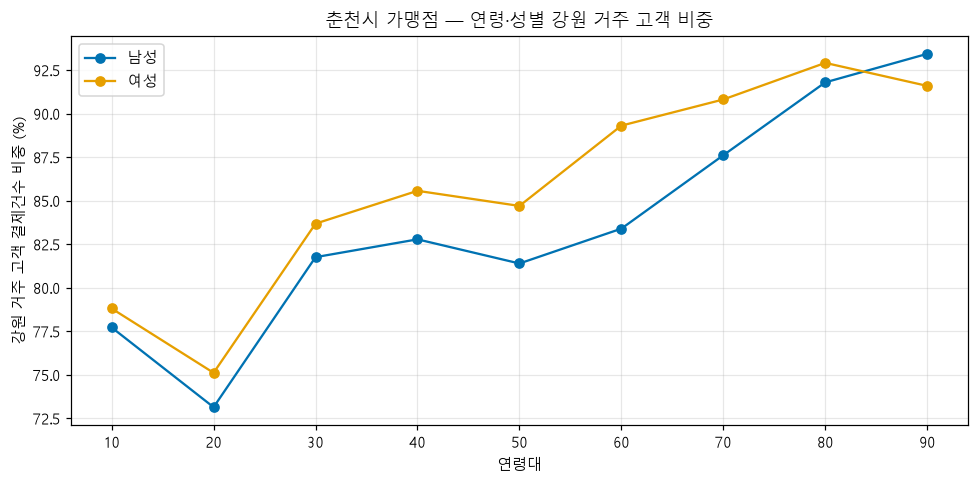

In [20]:
cc = card[card.MCT_SGG_CD == "강원 춘천시"]
local = cc.groupby(["SEX_CCD", "age_band"], observed=True).apply(
    lambda d: pd.Series({
        "강원거주_건수비중%": d.loc[d.is_local, "USE_CNT"].sum() / d.USE_CNT.sum() * 100,
        "정보없음%": d.loc[d.CLN_SGG_CD == "정보없음", "USE_CNT"].sum() / d.USE_CNT.sum() * 100,
    }), include_groups=False).reset_index()
piv_l = local.pivot(index="SEX_CCD", columns="age_band", values="강원거주_건수비중%")
print("춘천시 가맹점 — 강원 거주 고객 결제건수 비중 (%)")
print(piv_l.round(2).to_string())
print()
print(f"춘천 전체 강원거주 비중: "
      f"{cc.loc[cc.is_local, 'USE_CNT'].sum() / cc.USE_CNT.sum() * 100:.2f}%")

gn = card[card.MCT_SGG_CD == "서울 강남구"]
print(f"강남 전체 서울거주 비중: "
      f"{gn.loc[gn.CLN_SGG_CD == '서울', 'USE_CNT'].sum() / gn.USE_CNT.sum() * 100:.2f}%")
print("  (단 '서울'은 시도 단위라 강남구민 여부를 알 수 없다. 지역민 지표로 쓰지 않는다)")

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, s in enumerate(piv_l.index):
    ax.plot(piv_l.columns, piv_l.loc[s], marker="o", label=s, color=PALETTE[i])
ax.set_title("춘천시 가맹점 — 연령·성별 강원 거주 고객 비중")
ax.set_xlabel("연령대")
ax.set_ylabel("강원 거주 고객 결제건수 비중 (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 핵심 발견

이 절의 수치는 위 셀 출력에서 직접 읽는다. 해석은 아래와 같다.

**1. 춘천은 고령, 강남은 청·장년.**
60대 이상 유동인구 비중이 춘천에서 뚜렷하게 높고, 동별로도 춘천 읍면 지역이 상위를 차지한다.
고립 위험군 중 독거노인 유형을 본다면 춘천이 주 무대가 된다.

**2. 시간대 패턴 군집은 실재하는 구조이며, 지역 구분이 아니다.**
실루엣 0.42는 절대 기준으로 중간이지만 순열 귀무분포(평균 0.055) 대비 p<0.001이고,
부트스트랩 300회 ARI 평균 0.89, KMeans·Ward·GMM이 거의 같은 분할을 준다.
결정적으로 **ARI(군집, 지역) = 0.02**로 군집은 강남/춘천 구분과 무관하다.
소수 군집 10개는 춘천 8 + 강남 2이며, 춘천 동의 32% / 강남 동의 9%가 여기 속한다
(Cramér's V 0.28, 순열 p=0.078 — 약한 경향은 있으나 유의하지 않다).
즉 "저활동 정체형"은 지역과 별개로 존재하는 생활 패턴이다.

**3. 카드 집단축에서 고령 집단은 표본이 얇다.**
1단계에서 확인한 비식별 컷 편향과 같은 방향이다.
90대 집단의 지표는 절단 편향이 크므로 해석에 주의한다.

**다음 단계** — 3단계에서 4축 지표를 산출하고 민감도·강건성을 확인한다.